# Experiment 8 — Expert score aggregation

Compare CombMAX, CombMIN, CombSUM, CombMNZ, CombMEAN, and Discounted CombSUM on identical BM25F document rankings.

**Important:** Raw methods treat repeated course offerings as separate matches; only the discounted baseline reduces their contributions. This is part of the method comparison and should be stated as a limitation. CombMIN is especially sensitive to weak matching documents.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
root = Path('bm25_aggregation_results')
if not root.exists(): root = Path('testing/bm25_aggregation_results')
summary = pd.read_csv(root/'summary.csv')
metrics = pd.read_csv(root/'metrics.csv')
rankings = pd.read_csv(root/'rankings.csv')
plots = root/'plots'
plots.mkdir(exist_ok=True)
display(summary[summary.query_type=='overall'].sort_values('known_ndcg_at_k',ascending=False).round(4))

,method,query_type,queries,known_ndcg_at_k,known_mrr_at_k,known_recall_at_k,known_hits_at_k
15,discounted_combsum,overall,452,0.3332,0.3069,0.4683,0.5708
6,combsum,overall,452,0.3004,0.2647,0.4517,0.5509
0,combmax,overall,452,0.2974,0.2647,0.4353,0.5442
9,combmnz,overall,452,0.2927,0.2576,0.4425,0.5398
12,combmean,overall,452,0.1768,0.1318,0.3355,0.4137
3,combmin,overall,452,0.0646,0.0509,0.1212,0.1504


## Overall metric comparison

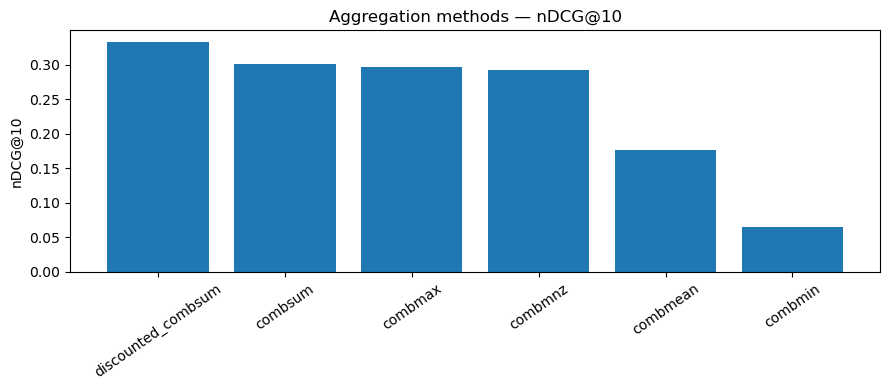

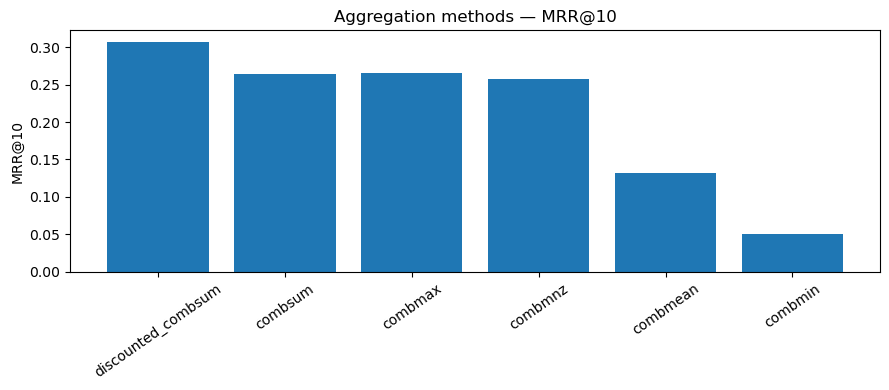

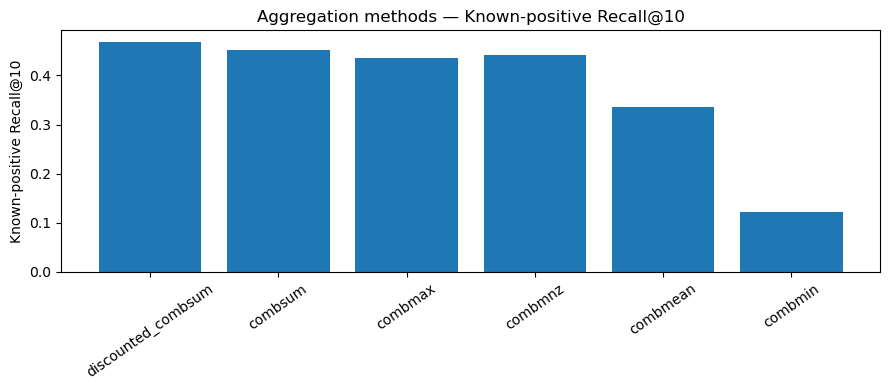

In [2]:
overall = summary[summary.query_type=='overall'].sort_values('known_ndcg_at_k',ascending=False)
for metric, label in [('known_ndcg_at_k','nDCG@10'),('known_mrr_at_k','MRR@10'),('known_recall_at_k','Known-positive Recall@10')]:
    fig,ax=plt.subplots(figsize=(9,4))
    ax.bar(overall.method, overall[metric])
    ax.set(ylabel=label,title=f'Aggregation methods — {label}')
    ax.tick_params(axis='x',rotation=35)
    fig.tight_layout()
    fig.savefig(plots/f'overall_{metric}.png',dpi=180)
    plt.show()

## Academic vs student-style queries

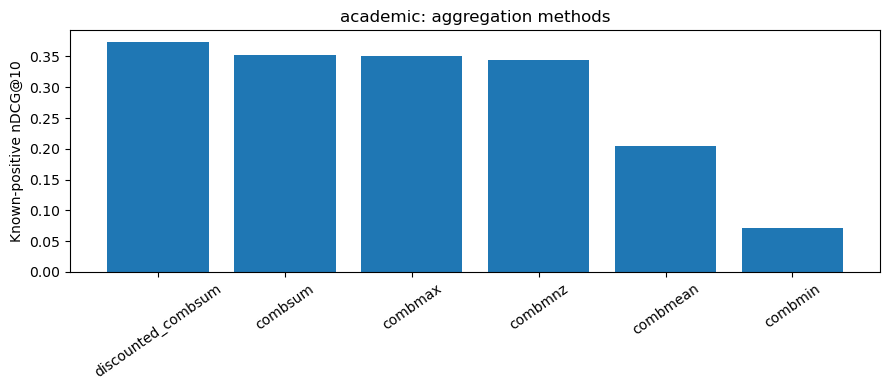

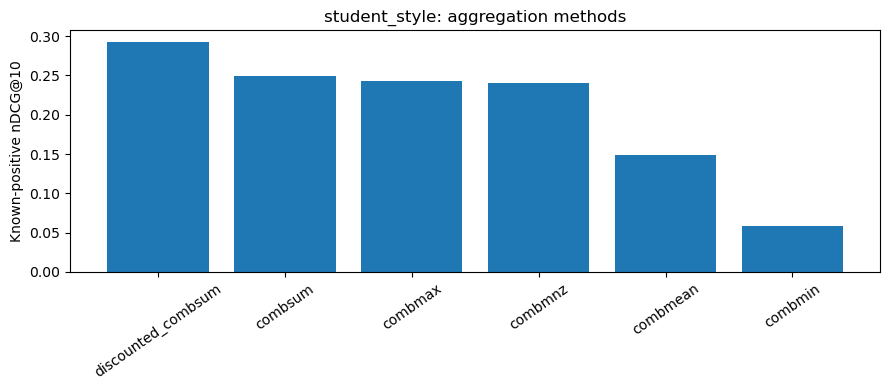

In [3]:
for group, frame in summary[summary.query_type!='overall'].groupby('query_type'):
    fig,ax=plt.subplots(figsize=(9,4))
    frame=frame.sort_values('known_ndcg_at_k',ascending=False)
    ax.bar(frame.method,frame.known_ndcg_at_k)
    ax.set(ylabel='Known-positive nDCG@10',title=f'{group}: aggregation methods')
    ax.tick_params(axis='x',rotation=35)
    fig.tight_layout()
    fig.savefig(plots/f'ndcg_{group}.png',dpi=180)
    plt.show()

## Paired query-level comparison against Discounted CombSUM

Descriptive bootstrap confidence intervals. If methods are selected on the same queries, these comparisons are exploratory. Shared source articles may make queries dependent.

In [4]:
wide=metrics.pivot(index='query_id',columns='method',values='known_ndcg_at_k')
base='discounted_combsum'
rng=np.random.default_rng(42)
rows=[]
for method in wide.columns:
    if method==base: continue
    pair=wide[[base,method]].dropna()
    d=(pair[method]-pair[base]).to_numpy()
    boots=np.array([rng.choice(d,size=len(d),replace=True).mean() for _ in range(5000)])
    rows.append(dict(method=method,mean_delta=d.mean(),ci_low=np.quantile(boots,.025),ci_high=np.quantile(boots,.975),improved=(d>0).sum(),worsened=(d<0).sum(),unchanged=(d==0).sum()))
display(pd.DataFrame(rows).sort_values('mean_delta',ascending=False).round(4))

,method,mean_delta,ci_low,ci_high,improved,worsened,unchanged
4,combsum,-0.0328,-0.0434,-0.0229,18,104,330
0,combmax,-0.0358,-0.0583,-0.0139,62,112,278
3,combmnz,-0.0406,-0.0523,-0.0293,24,108,320
1,combmean,-0.1564,-0.1891,-0.1241,48,189,215
2,combmin,-0.2686,-0.3087,-0.2281,42,213,197


## Researcher ranking stability

In [5]:
base=rankings[rankings.method=='discounted_combsum']
base_sets={qid:set(g.researcher_uuid) for qid,g in base.groupby('query_id')}
rows=[]
for method, frame in rankings.groupby('method'):
    if method=='discounted_combsum':continue
    overlap=[]
    for qid,g in frame.groupby('query_id'):
        overlap.append(len(set(g.researcher_uuid)&base_sets[qid]))
    rows.append({'method':method,'mean_top10_overlap':np.mean(overlap)})
display(pd.DataFrame(rows).sort_values('mean_top10_overlap',ascending=False).round(2))

,method,mean_top10_overlap
4,combsum,8.71
3,combmnz,8.54
0,combmax,5.38
1,combmean,3.58
2,combmin,1.61


### Experiment 8: Comparison of Expert Score Aggregation Methods

Six expert score aggregation methods were evaluated: CombMAX, CombMIN, CombSUM, CombMNZ, CombMEAN, and Discounted CombSUM. All methods were evaluated using the same 452 queries, with stemming and stopword removal enabled, uniform field weights, and a document retrieval depth of 100.

Discounted CombSUM achieved the highest performance across all three evaluation metrics, with an nDCG@10 of 0.3332, MRR@10 of 0.3069, and known-positive Recall@10 of 0.4683. Compared with standard CombSUM (nDCG@10 = 0.3004), this represents a relative improvement of approximately 10.9%.

CombMAX achieved an nDCG@10 of 0.2974, suggesting that relying exclusively on the highest-scoring document per researcher was less effective than aggregating evidence across multiple documents. CombMNZ performed similarly to standard CombSUM but did not improve retrieval effectiveness. CombMEAN and CombMIN performed substantially worse.

The ranking overlap analysis further demonstrated that CombSUM and CombMNZ produced relatively similar top-10 researcher sets to Discounted CombSUM, while CombMAX, CombMEAN, and CombMIN introduced considerably greater changes.

These findings support retaining Discounted CombSUM for subsequent experiments. Its treatment of repeated course offerings appears beneficial in the evaluated collection, although the comparison also changes the handling of duplicates rather than isolating the aggregation operator alone.

The findings should be interpreted in light of incomplete relevance judgments and possible dependencies between queries originating from the same source articles.